In [3]:
NAMA = 'Wandi'
NIM  = '244107020003'
print('NAMA :', NAMA)
print('NIM  :', NIM)


NAMA : Wandi
NIM  : 244107020003


# Modul 7 - Segmentasi Citra dengan Thresholding

Tugas individu (D1): global threshold, adaptive threshold, Otsu, segmentasi berbasis wilayah,
dan segmentasi warna K-Means.

Thresholding dibuat manual pakai NumPy. OpenCV cuma dipakai buat ngecek hasilnya.


## Persiapan

Mount Drive dan import library.

In [4]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [5]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt
from collections import deque
from skimage import data, segmentation
from sklearn.cluster import KMeans
import os


In [6]:
CONTOH = '/content/drive/MyDrive/PCVK/Images'
BASE   = CONTOH + '/' + NIM        


def tampil(img, judul, cmap=None):
    if img.ndim == 2:
        plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    else:
        plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title(NIM + ' - ' + judul, fontsize=9)
    plt.axis('off')


def muat(kandidat, mode=cv.IMREAD_GRAYSCALE, cadangan=None, nama=''):
    """Coba beberapa path, kembalikan citra pertama yang berhasil dibaca."""
    for p in kandidat:
        img = cv.imread(p, mode)
        if img is not None:
            print('dimuat dari :', p)
            return img
    print('TIDAK ADA   :', kandidat)
    if cadangan is not None:
        print('              -> pakai cadangan', nama)
    return cadangan


def gradient_cadangan(h=256, w=256):
    """Gradient horizontal 0..255, cadangan kalau gradient.jpg tidak ada."""
    x = np.linspace(0, 255, w).astype(np.uint8)
    return np.tile(x, (h, 1))


def ke_gray(citra):
    """Pastikan citra cadangan dalam bentuk grayscale."""
    return citra if citra.ndim == 2 else cv.cvtColor(citra, cv.COLOR_RGB2GRAY)


print('isi folder contoh :', sorted(os.listdir(CONTOH)) if os.path.isdir(CONTOH) else 'folder belum ada')
print('isi folder KTP    :', sorted(os.listdir(BASE)) if os.path.isdir(BASE) else 'folder belum ada')


isi folder contoh : ['244107020003', 'Lenna.png', 'WhatsApp Image 2026-10-12 at 07.38.31.jpeg', 'djawatan.jpg', 'gradient.jpg', 'lena_gs_lc2.jpg', 'mandrill.tiff', 'sudoku-original.jpg']
isi folder KTP    : ['ktp.jpg']


---
# D1-3 Global Threshold manual (thresh = 200)

Lima jenis threshold, dibuat manual semua.

| Jenis | Jika piksel > thresh | Jika piksel <= thresh |
|---|---|---|
| BINARY | jadi 255 | jadi 0 |
| BINARY_INV | jadi 0 | jadi 255 |
| TRUNC | jadi thresh | nilai asli |
| TOZERO | nilai asli | jadi 0 |
| TOZERO_INV | jadi 0 | nilai asli |


In [7]:
# Kelima jenis global threshold, semuanya manual (tanpa cv.threshold)
def th_binary(gray, T, maxval=255):
    return np.where(gray > T, maxval, 0).astype(np.uint8)


def th_binary_inv(gray, T, maxval=255):
    return np.where(gray > T, 0, maxval).astype(np.uint8)


def th_trunc(gray, T):
    return np.where(gray > T, T, gray).astype(np.uint8)


def th_tozero(gray, T):
    return np.where(gray > T, gray, 0).astype(np.uint8)


def th_tozero_inv(gray, T):
    return np.where(gray > T, 0, gray).astype(np.uint8)


dimuat dari : /content/drive/MyDrive/PCVK/Images/gradient.jpg


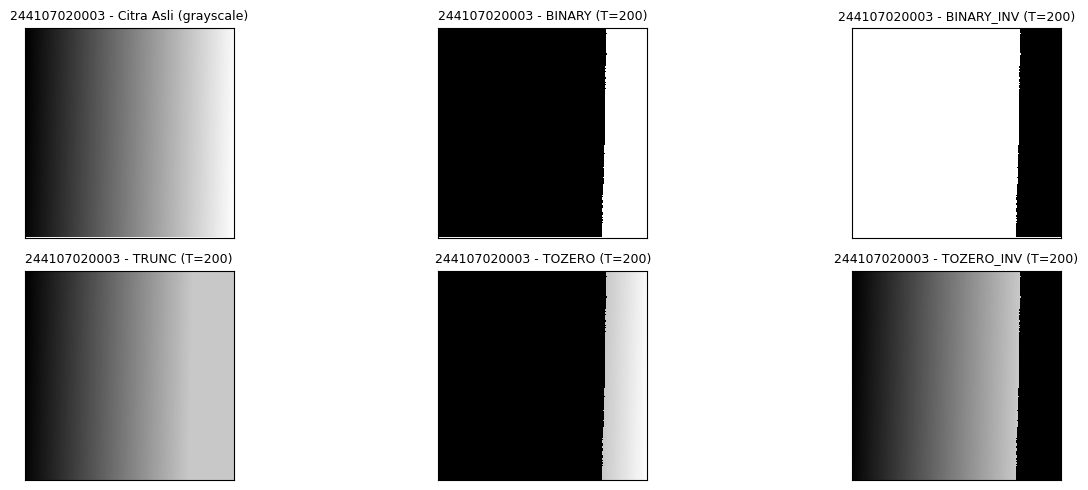

In [8]:
T = 200
gray = muat([CONTOH + '/gradient.jpg', BASE + '/gradient.jpg'],
            cv.IMREAD_GRAYSCALE, gradient_cadangan(), 'gradient buatan')

hasil = [gray, th_binary(gray, T), th_binary_inv(gray, T),
         th_trunc(gray, T), th_tozero(gray, T), th_tozero_inv(gray, T)]
judul = ['Citra Asli (grayscale)', 'BINARY (T=%d)' % T, 'BINARY_INV (T=%d)' % T,
         'TRUNC (T=%d)' % T, 'TOZERO (T=%d)' % T, 'TOZERO_INV (T=%d)' % T]

plt.figure(figsize=(14, 5))
for i, (im, t) in enumerate(zip(hasil, judul)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
    plt.title(NIM + ' - ' + t, fontsize=9)
    plt.xticks([]); plt.yticks([])
plt.tight_layout(); plt.show()


BINARY dan BINARY_INV saling kebalikan. TRUNC memotong nilai di atas T jadi rata. TOZERO
menyisakan bagian terang, TOZERO_INV menyisakan bagian gelap.


In [9]:
# Verifikasi: hasil manual harus sama persis dengan cv.threshold
pasangan = [
    ('BINARY',     th_binary(gray, T),     cv.THRESH_BINARY),
    ('BINARY_INV', th_binary_inv(gray, T), cv.THRESH_BINARY_INV),
    ('TRUNC',      th_trunc(gray, T),      cv.THRESH_TRUNC),
    ('TOZERO',     th_tozero(gray, T),     cv.THRESH_TOZERO),
    ('TOZERO_INV', th_tozero_inv(gray, T), cv.THRESH_TOZERO_INV),
]
for nama, manual, kode in pasangan:
    pustaka = cv.threshold(gray, T, 255, kode)[1]
    selisih = int(np.abs(manual.astype(int) - pustaka.astype(int)).max())
    print('%-11s selisih maksimum vs cv.threshold = %d' % (nama, selisih))


BINARY      selisih maksimum vs cv.threshold = 0
BINARY_INV  selisih maksimum vs cv.threshold = 0
TRUNC       selisih maksimum vs cv.threshold = 0
TOZERO      selisih maksimum vs cv.threshold = 0
TOZERO_INV  selisih maksimum vs cv.threshold = 0


---
# D1-4 Adaptive Threshold manual

Global threshold pakai T = 127, jendela 11x11, C = 2, sigma = 2 buat Gaussian. Konvolusinya
dihitung sendiri, tanpa cv.threshold / cv.adaptiveThreshold / fungsi filter.

Rumusnya T(x,y) = mu(x,y) - C, mu = rata-rata lokal. Untuk Gaussian, mu_G pakai kernel
Gaussian 2D sigma=2.


In [10]:
# Konvolusi manual. padding 'edge' meniru BORDER_REPLICATE milik OpenCV.
def konvolusi(gray, kernel):
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2
    h, w = gray.shape
    pad = np.pad(gray.astype(np.float64), ((ph, ph), (pw, pw)), mode='edge')
    out = np.zeros((h, w), dtype=np.float64)
    for i in range(kh):
        for j in range(kw):
            bobot = kernel[i, j]
            if bobot != 0:
                out += bobot * pad[i:i + h, j:j + w]
    return out


def global_manual(gray, T, maxval=255):
    return np.where(gray > T, maxval, 0).astype(np.uint8)


def adaptive_mean_manual(gray, block=11, C=2):
    kernel = np.ones((block, block), dtype=np.float64) / (block * block)
    rata2 = konvolusi(gray, kernel)      # mu(x, y)
    ambang = rata2 - C                   # T(x, y) = mu - C
    return np.where(gray > ambang, 255, 0).astype(np.uint8)


def kernel_gaussian_1d(ukuran, sigma):
    sumbu = np.arange(ukuran) - ukuran // 2
    k = np.exp(-(sumbu ** 2) / (2.0 * sigma ** 2))
    return k / k.sum()


def adaptive_gaussian_manual(gray, block=11, C=2, sigma=2):
    k1d = kernel_gaussian_1d(block, sigma)
    kernel = np.outer(k1d, k1d)          # kernel Gaussian 2D, sudah dinormalisasi
    rata2 = konvolusi(gray, kernel)      # mu_G(x, y)
    ambang = rata2 - C
    return np.where(gray > ambang, 255, 0).astype(np.uint8)


dimuat dari : /content/drive/MyDrive/PCVK/Images/sudoku-original.jpg


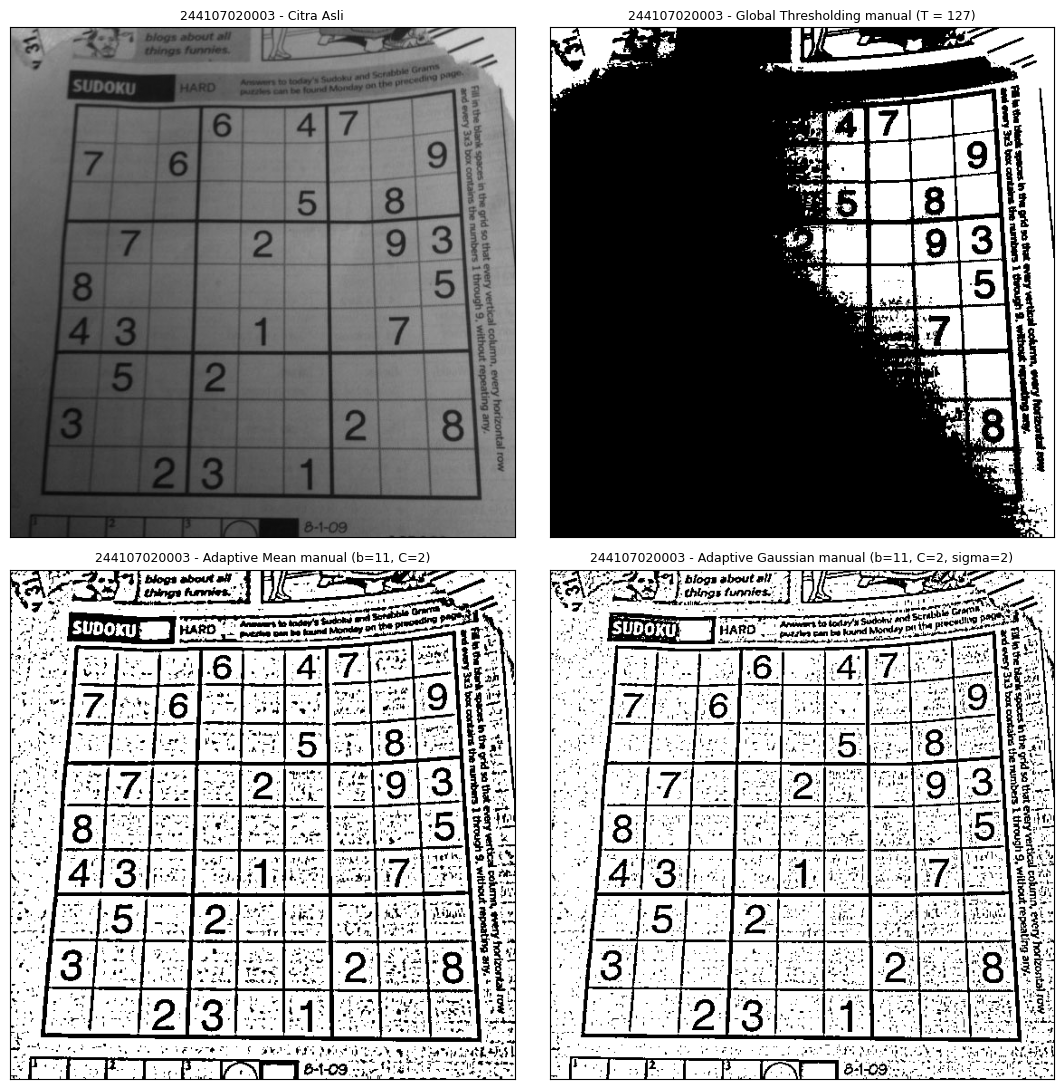

In [11]:
sudoku = muat([CONTOH + '/sudoku-original.jpg', BASE + '/sudoku-original.jpg'],
              cv.IMREAD_GRAYSCALE, ke_gray(data.page()), 'skimage.data.page')

th_global = global_manual(sudoku, 127)
th_mean   = adaptive_mean_manual(sudoku, 11, 2)
th_gauss  = adaptive_gaussian_manual(sudoku, 11, 2, 2)

hasil = [sudoku, th_global, th_mean, th_gauss]
judul = ['Citra Asli', 'Global Thresholding manual (T = 127)',
         'Adaptive Mean manual (b=11, C=2)',
         'Adaptive Gaussian manual (b=11, C=2, sigma=2)']

plt.figure(figsize=(11, 11))
for i, (im, t) in enumerate(zip(hasil, judul)):
    plt.subplot(2, 2, i + 1)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(NIM + ' - ' + t, fontsize=9)
    plt.xticks([]); plt.yticks([])
plt.tight_layout(); plt.show()


In [12]:
# Verifikasi manual vs OpenCV. Ini cuma pembanding, hasil utama tetap versi manual.
ref_mean  = cv.adaptiveThreshold(sudoku, 255, cv.ADAPTIVE_THRESH_MEAN_C,
                                 cv.THRESH_BINARY, 11, 2)
ref_gauss = cv.adaptiveThreshold(sudoku, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv.THRESH_BINARY, 11, 2)

for nama, manual, pustaka in [('mean', th_mean, ref_mean),
                              ('gaussian', th_gauss, ref_gauss)]:
    beda = (manual != pustaka).mean() * 100
    print('adaptive %-8s: piksel yang berbeda dari OpenCV = %.2f%%' % (nama, beda))


adaptive mean    : piksel yang berbeda dari OpenCV = 2.67%
adaptive gaussian: piksel yang berbeda dari OpenCV = 2.83%


Di sudoku yang pencahayaannya tidak merata, global 127 gagal: sisi gelap ikut jadi hitam dan
tulisannya hilang. Adaptive mean dan Gaussian tetap kebaca karena ambangnya per lingkungan
lokal. Hasil manual hampir sama dengan OpenCV, beda cuma di tepi citra. sigma=2 kebetulan
memang default OpenCV buat blockSize 11.


---
# D1-5 Otsu Threshold manual

Otsu cari T yang maksimalkan between-class variance w_b * w_f * (mu_b - mu_f)^2.


In [13]:
def otsu_manual(gray):
    """Otsu tanpa library: cari T yang memaksimalkan between-class variance."""
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])                # jumlah piksel background
        pcf = np.sum(his[t:])                # jumlah piksel foreground
        if pcb == 0 or pcf == 0:             # lewati kelas yang kosong
            continue
        Wb = pcb * mean_weight               # bobot background
        Wf = pcf * mean_weight               # bobot foreground
        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2   # between-class variance
        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = gray.copy()
    final_img[gray > final_thresh] = 255
    final_img[gray <= final_thresh] = 0
    return final_img, final_thresh, final_value


dimuat dari : /content/drive/MyDrive/PCVK/Images/lena_gs_lc2.jpg
nilai threshold hasil Otsu manual : 95
between-class variance maksimum   : 16.084875820482857
threshold Otsu versi library      : 94.0


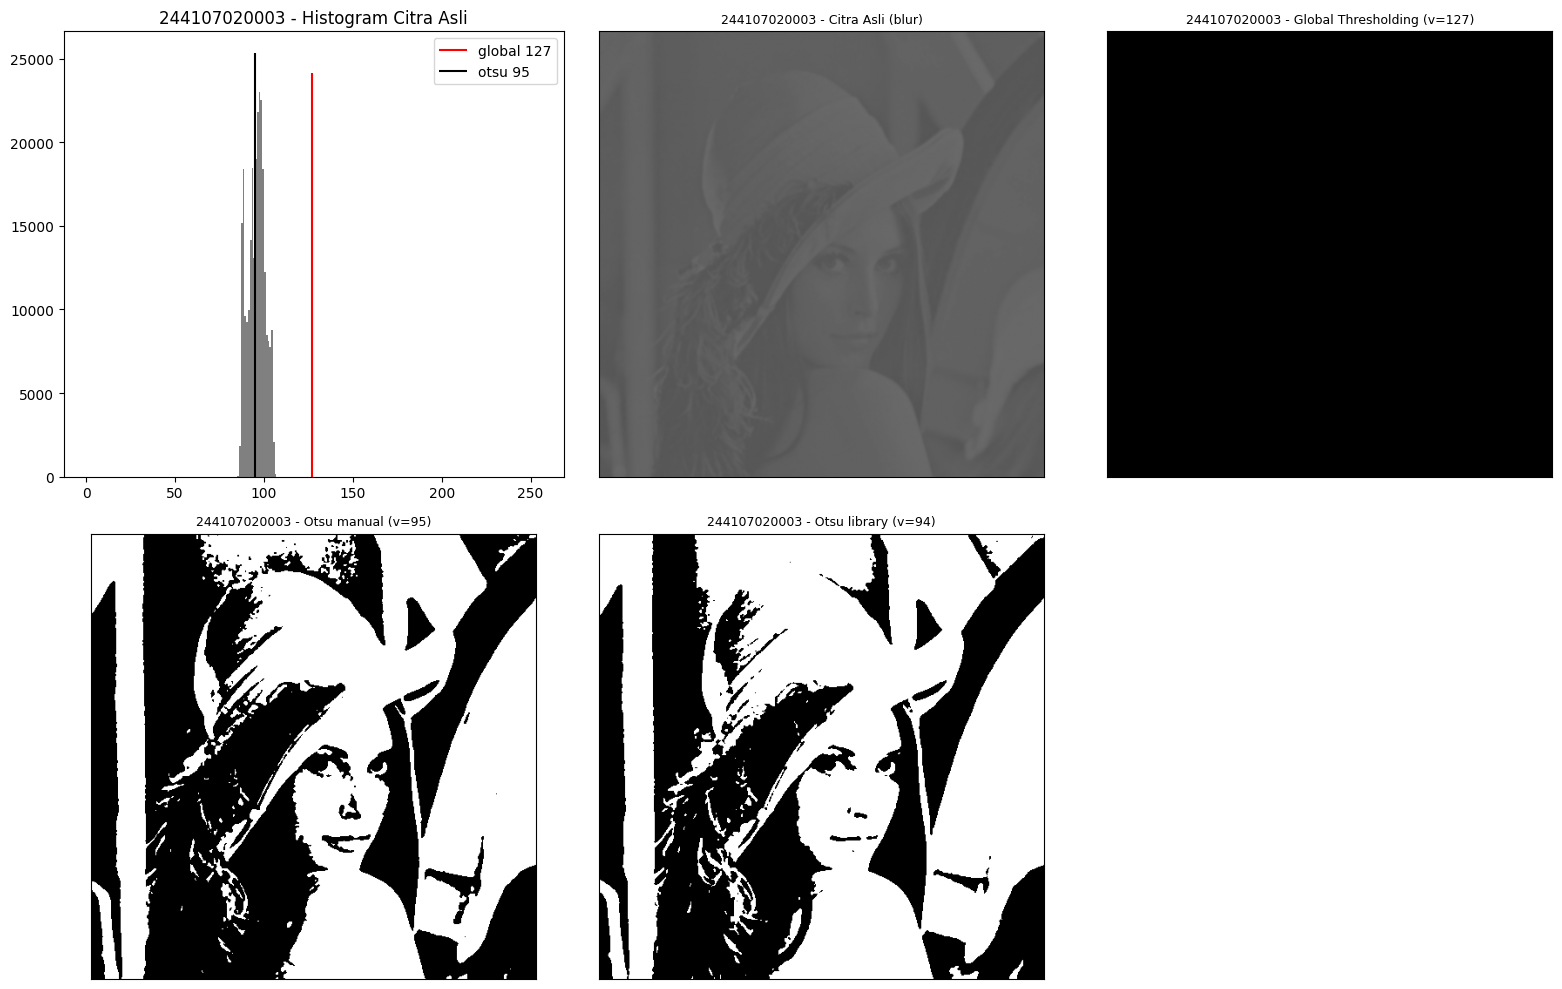

In [17]:
lena_lc = muat([CONTOH + '/lena_gs_lc2.jpg', BASE + '/lena_gs_lc2.jpg'],
               cv.IMREAD_GRAYSCALE, ke_gray(data.camera()), 'skimage.data.camera')
blur = cv.GaussianBlur(lena_lc, (5, 5), 0)

otsu_biner, otsu_thresh, otsu_val = otsu_manual(blur)
print('nilai threshold hasil Otsu manual :', otsu_thresh)
print('between-class variance maksimum   :', otsu_val)

ret, th1 = cv.threshold(blur, 127, 255, cv.THRESH_BINARY)
ret2, th2 = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
print('threshold Otsu versi library      :', ret2)

judul = ['Citra Asli (blur)', 'Global Thresholding (v=127)',
         "Otsu manual (v=%d)" % otsu_thresh, "Otsu library (v=%d)" % ret2]
citra3 = [blur, th1, otsu_biner, th2]

plt.figure(figsize=(16, 10))
plt.subplot(2, 3, 1)
plt.hist(blur.ravel(), 256, range=[0, 256], color='gray')
plt.vlines(127, 0, plt.ylim()[1], colors='red', label='global 127')
plt.vlines(otsu_thresh, 0, plt.ylim()[1], colors='black', label="otsu %d" % otsu_thresh)
plt.title(NIM + ' - Histogram Citra Asli')
plt.legend()
for i in range(len(citra3)):
    plt.subplot(2, 3, i + 2)
    plt.imshow(citra3[i], 'gray', vmin=0, vmax=255)
    plt.title(NIM + ' - ' + judul[i], fontsize=9)
    plt.xticks([]); plt.yticks([])
plt.tight_layout(); plt.show()


## Pertanyaan D1-5A

**Kenapa binary threshold (v=127) hitam semua?**

lena_gs_lc2 low contrast, nilainya cuma di rentang 85-108. Karena 127 > 108, tidak ada piksel
yang lolos f(x,y) > 127, jadi semua jadi 0. Di histogram, semua batang ada di kiri garis 127.

**Berapa ambang supaya Lena masih kelihatan?**

Ambangnya harus masuk ke rentang intensitas citra, sekitar titik tengah (85+108)/2 = 96.
Hasil Otsu di atas keluar di sekitar 95, jadi ambang 90-an sudah cukup.


## D1-5B Otsu pada citra KTP sendiri


dimuat dari : /content/drive/MyDrive/PCVK/Images/244107020003/ktp.jpg
threshold Otsu pada KTP : 166


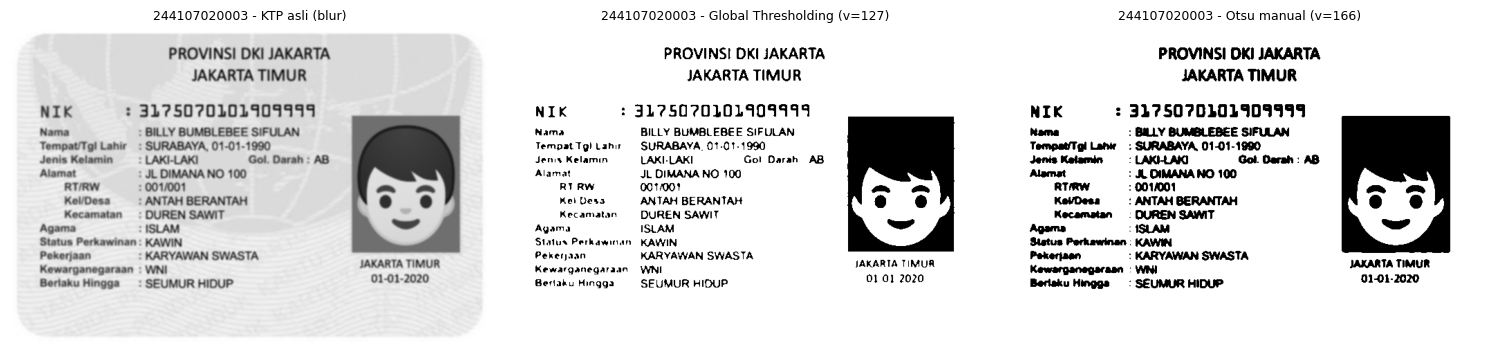

In [18]:
ktp_gray = muat([BASE + '/ktp.jpg', BASE + '/KTP.jpg', BASE + '/ktp_fulan.jpg',
                   CONTOH + '/ktp_fulan.jpg'], cv.IMREAD_GRAYSCALE, None)

if ktp_gray is None:
    print('citra KTP belum ada di', BASE, '- silakan taruh berkas KTP dulu, lalu jalankan ulang sel ini.')
else:
    ktp_blur = cv.GaussianBlur(ktp_gray, (5, 5), 0)
    ktp_otsu, ktp_thresh, _ = otsu_manual(ktp_blur)
    ret_ktp, ktp_global = cv.threshold(ktp_blur, 127, 255, cv.THRESH_BINARY)
    print('threshold Otsu pada KTP :', ktp_thresh)

    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1); tampil(ktp_blur, 'KTP asli (blur)')
    plt.subplot(1, 3, 2); tampil(ktp_global, 'Global Thresholding (v=127)')
    plt.subplot(1, 3, 3); tampil(ktp_otsu, "Otsu manual (v=%d)" % ktp_thresh)
    plt.tight_layout(); plt.show()


Di KTP, Otsu biasanya lebih bagus dari ambang tetap 127 karena ambangnya dihitung dari
histogram kartu itu sendiri. Tapi tetap tergantung kontras: kalau latar dan tulisannya
sama-sama terang, Otsu bisa ikut memisahkan area yang bukan tulisan.


---
# D1-6 Segmentasi berbasis wilayah

Pakai citra data.coins() dari skimage.


## D1-6A Region growing manual

In [19]:
def region_growing(gray, seed, T, konektivitas=8):
    """Region growing manual: tumbuhkan region dari seed selama |I - mu_region| < T."""
    h, w = gray.shape
    if konektivitas == 8:
        tetangga = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
    else:
        tetangga = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    gy, gx = seed
    mask = np.zeros((h, w), dtype=bool)
    visited = np.zeros((h, w), dtype=bool)
    antre = deque([seed])
    visited[gy, gx] = True
    mask[gy, gx] = True
    total = float(gray[gy, gx])
    jumlah = 1

    while antre:
        y, x = antre.popleft()
        mu = total / jumlah                     # rata-rata region saat ini
        for dy, dx in tetangga:
            ny, nx = y + dy, x + dx
            if 0 <= ny < h and 0 <= nx < w and not visited[ny, nx]:
                if abs(float(gray[ny, nx]) - mu) < T:
                    visited[ny, nx] = True
                    mask[ny, nx] = True
                    total += float(gray[ny, nx])
                    jumlah += 1
                    antre.append((ny, nx))
    return mask


def overlay_region(gray, mask, seed):
    """Tandai region dengan warna merah, seed dengan kotak putih."""
    rgb = np.stack([gray] * 3, axis=-1).astype(np.float64)
    rgb[mask] = 0.45 * rgb[mask] + 0.55 * np.array([255, 60, 60])
    rgb = np.clip(rgb, 0, 255).astype(np.uint8)
    sy, sx = seed
    rgb[max(0, sy - 4):sy + 5, max(0, sx - 4):sx + 5] = [255, 255, 255]
    return rgb


In [20]:
coins = data.coins()        # citra grayscale 303 x 384

# Tiga seed ditentukan dengan melihat langsung citra coins (koordinat = baris, kolom):
#  - di dalam koin : pusat salah satu koin, area terang (nilai 188)
#  - di latar      : sudut kanan bawah, area gelap antar koin (nilai 8)
#  - di tepi koin  : tepat di batas atas koin yang sama, area transisi (nilai 109)
seeds = [
    ('di dalam koin', (193, 212)),
    ('di latar',      (301, 383)),
    ('di tepi koin',  (173, 224)),
]
for nama, s in seeds:
    print('seed %-13s (baris, kolom) = (%d, %d), nilai = %d' % (nama, s[0], s[1], coins[s]))


seed di dalam koin (baris, kolom) = (193, 212), nilai = 188
seed di latar      (baris, kolom) = (301, 383), nilai = 8
seed di tepi koin  (baris, kolom) = (173, 224), nilai = 109


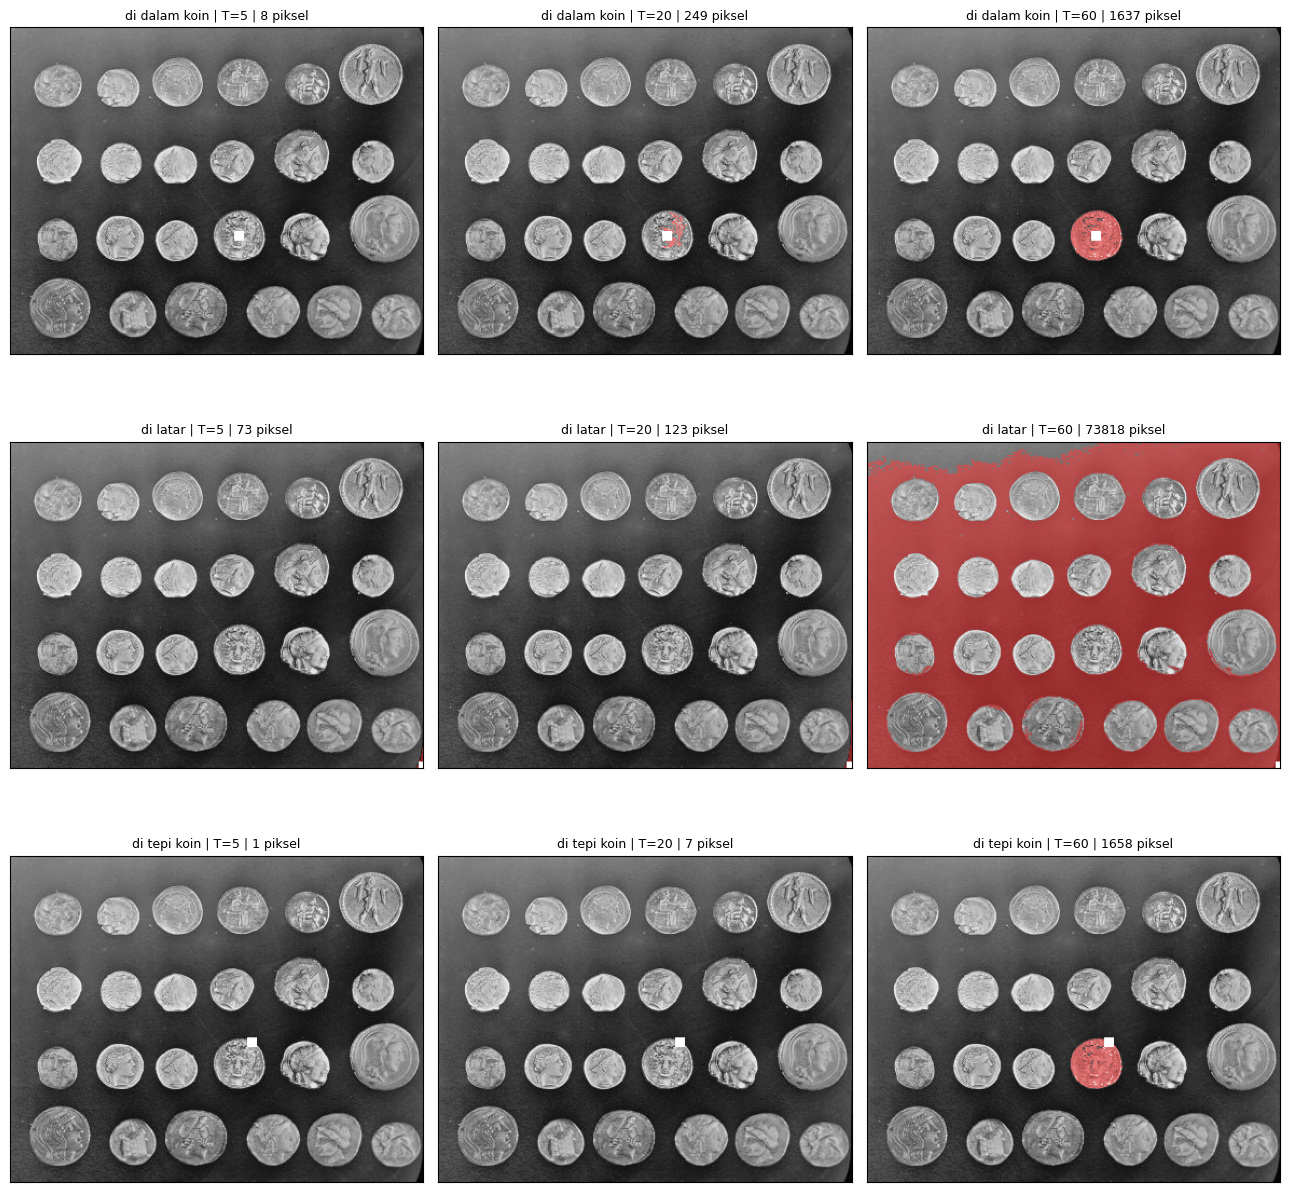

In [21]:
nilai_T = [5, 20, 60]

plt.figure(figsize=(13, 13))
for r, (nama, seed) in enumerate(seeds):
    for c, T in enumerate(nilai_T):
        mask = region_growing(coins, seed, T)
        plt.subplot(3, 3, r * 3 + c + 1)
        plt.imshow(overlay_region(coins, mask, seed))
        plt.title('%s | T=%d | %d piksel' % (nama, T, int(mask.sum())), fontsize=9)
        plt.xticks([]); plt.yticks([])
plt.tight_layout(); plt.show()


Baca gridnya: baris = seed, kolom = T.

Seed di dalam koin: T=5 cuma bercak kecil, T=20 mengisi koin, T=60 mulai bocor keluar. Seed
di latar: tumbuh cepat karena latarnya homogen. Seed di tepi: regionnya cuma memanjang di
batas koin, tidak mengisi koinnya.

Jadi hasilnya sangat tergantung posisi seed dan nilai T.


## D1-6B flood fill (skimage.segmentation.flood)


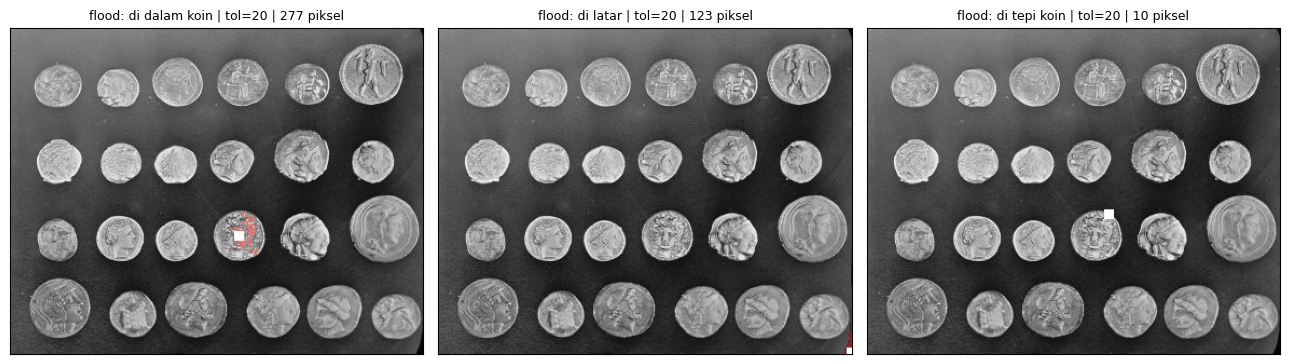

In [22]:
plt.figure(figsize=(13, 5))
for i, (nama, seed) in enumerate(seeds):
    mask = segmentation.flood(coins, seed, tolerance=20)
    plt.subplot(1, 3, i + 1)
    plt.imshow(overlay_region(coins, mask, seed))
    plt.title('flood: %s | tol=20 | %d piksel' % (nama, int(mask.sum())), fontsize=9)
    plt.xticks([]); plt.yticks([])
plt.tight_layout(); plt.show()


flood() menerima piksel terhubung yang selisihnya terhadap intensitas seed masih dalam
toleransi. Bedanya dengan versi manual: flood bandingin ke nilai seed, versi manual ke
rata-rata region yang berubah terus. Toleransi kecil = region sempit, besar = meluas.


---
# D1-7 Segmentasi warna K-Means (hanya biru)

Piksel dikelompokkan di ruang HSV pakai K-Means, cluster yang pusatnya di rentang biru
(H 85-130, S>=25, V>=40) yang ditampilkan.


dimuat dari : /content/drive/MyDrive/PCVK/Images/244107020003/ktp.jpg
pusat cluster (H, S, V):
  cluster 0 -> ( 100.7,  38.5, 245.2)   <-- BIRU
  cluster 1 -> (  70.2,  46.8,  78.6)
  cluster 2 -> (   9.9,  26.1, 248.4)
  cluster 3 -> (  98.7, 214.3,  25.8)
  cluster 4 -> (   3.5, 188.6, 212.2)


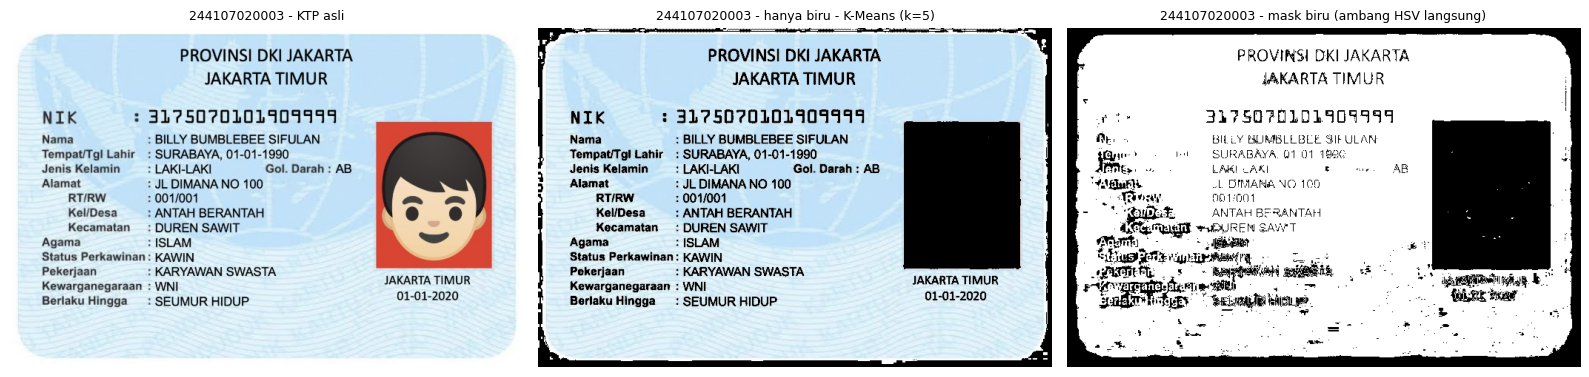

In [23]:
ktp_warna = muat([CONTOH + '/ktp_fulan.jpg', BASE + '/ktp_fulan.jpg',
                    BASE + '/ktp.jpg'], cv.IMREAD_COLOR, None)

if ktp_warna is None:
    print('citra ktp_fulan.jpg tidak ditemukan, lewati bagian ini.')
else:
    hsv = cv.cvtColor(ktp_warna, cv.COLOR_BGR2HSV)
    Z = hsv.reshape((-1, 3)).astype(np.float32)

    k = 5
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    label = kmeans.fit_predict(Z)
    pusat = kmeans.cluster_centers_          # pusat cluster di ruang HSV

    H, S, V = pusat[:, 0], pusat[:, 1], pusat[:, 2]
    biru = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)

    print('pusat cluster (H, S, V):')
    for i in range(k):
        tanda = '   <-- BIRU' if biru[i] else ''
        print('  cluster %d -> (%6.1f, %5.1f, %5.1f)%s'
              % (i, H[i], S[i], V[i], tanda))

    mask_klaster = biru[label].reshape(hsv.shape[:2])

    # pembanding: ambang HSV langsung sesuai petunjuk modul
    Hc, Sc, Vc = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]
    mask_langsung = (Hc >= 85) & (Hc <= 130) & (Sc >= 25) & (Vc >= 40)

    hasil = np.zeros_like(ktp_warna)
    hasil[mask_klaster] = ktp_warna[mask_klaster]

    plt.figure(figsize=(16, 5))
    plt.subplot(1, 3, 1); tampil(ktp_warna, 'KTP asli')
    plt.subplot(1, 3, 2); tampil(hasil, 'hanya biru - K-Means (k=%d)' % k)
    plt.subplot(1, 3, 3)
    plt.imshow(mask_langsung, cmap='gray')
    plt.title(NIM + ' - mask biru (ambang HSV langsung)', fontsize=9)
    plt.axis('off')
    plt.tight_layout(); plt.show()


K-Means memetakan tiap piksel ke warna cluster terdekat, jadi hasilnya lebih rapi dari ambang
HSV langsung. Naikkan k kalau mau pembagian warna lebih detail.
